# 04: Where and when do I have the most impact?

**Question:** when do my kills (and deaths) actually swing rounds, and where on the map am I worth the most?

Kills aren't equal. Getting the 5th kill when it's 4v1 does almost nothing; the opening kill in a 5v5 does a lot.
So instead of counting kills I use **win probability added (WPA)**:

1. Fit a simple model of *"how likely are we to win this round right now?"* from the state of the round: players alive on each side, side, bomb planted, and the money difference.
2. Every kill moves that number. A kill by me gets the change as **credit**; my death gets the change as a **cost**.
3. Add it up per round. +0.10 means I moved our win chance by 10 percentage points that round.

It's the same idea sports analysts use for "win probability added" in baseball and the NFL. Same 64 demos as before.

> 📝 = my own take.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

quality = pd.read_parquet(P / "demo_quality.parquet")
OK = set(quality.loc[quality["ok"], "match_id"])
KEY = ["match_id", "round"]

rf = pd.read_parquet(P / "round_features.parquet").query("match_id in @OK")
kills = pd.read_parquet(P / "kills.parquet").query("match_id in @OK and not after_round_end").sort_values(KEY + ["tick"])
pr = pd.read_parquet(P / "player_rounds.parquet").query("match_id in @OK")
pos = pd.read_parquet(P / "positions.parquet").query("match_id in @OK")

REGS = ["MlgSly", "Sad_X", "Inbail", "Toe_bias", "XxcanonboixX"]
MAPS = {m: m.replace("de_", "").title() for m in rf["map"].unique()}

plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
WIN, LOSS, NEUTRAL, US, THEM = "#2a9d8f", "#e76f51", "#6c757d", "#264653", "#e9c46a"

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. The win-probability model

out-of-sample AUC 0.872, Brier 0.146  (grouped by match)


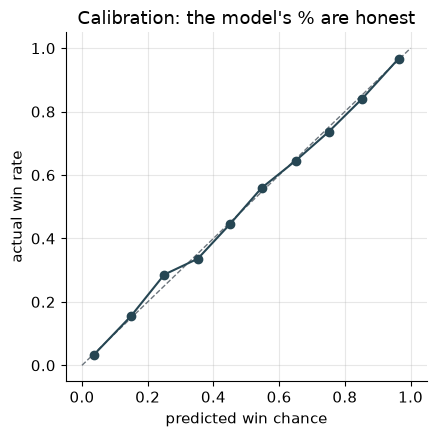

In [2]:
k = kills.merge(rf[KEY + ["map", "my_side", "my_team_won", "equip_diff", "bomb_planted", "plant_time_s", "is_pistol"]], on=KEY)
k["us_died"] = k["victim_is_my_team"].astype(int)
k["them_died"] = 1 - k["us_died"]
g = k.groupby(KEY)
k["us_after"] = 5 - g["us_died"].cumsum()
k["them_after"] = 5 - g["them_died"].cumsum()
k["us_before"] = k["us_after"] + k["us_died"]
k["them_before"] = k["them_after"] + k["them_died"]
k["planted"] = k["bomb_planted"] & (k["time_s"] > k["plant_time_s"])

def state(us, them, side, planted, equip_diff):
    X = pd.DataFrame({"us": us, "them": them, "diff": us - them, "ct": (side == "CT").astype(int),
                      "planted": planted.astype(int), "equip": equip_diff / 10_000})
    X["planted_ct"] = X["planted"] * X["ct"]
    X["diff_ct"] = X["diff"] * X["ct"]
    X["us_dead"] = (X["us"] == 0).astype(int)
    X["them_dead"] = (X["them"] == 0).astype(int)
    return X

five = pd.Series(5, index=rf.index)
X = pd.concat([state(five, five, rf["my_side"], pd.Series(False, index=rf.index), rf["equip_diff"]),   # round start
               state(k["us_after"], k["them_after"], k["my_side"], k["planted"], k["equip_diff"])])  # after every kill
y = pd.concat([rf["my_team_won"], k["my_team_won"]]).astype(int)
groups = pd.concat([rf["match_id"], k["match_id"]])

wp_model = LogisticRegression(max_iter=2000)
p = cross_val_predict(wp_model, X, y, groups=groups, cv=GroupKFold(5), method="predict_proba")[:, 1]
print(f"out-of-sample AUC {roc_auc_score(y, p):.3f}, Brier {brier_score_loss(y, p):.3f}  (grouped by match)")

cal = pd.DataFrame({"predicted": p, "actual": y.values})
cal["bucket"] = pd.cut(cal["predicted"], np.linspace(0, 1, 11))
cal = cal.groupby("bucket", observed=True).agg(n=("actual", "size"), predicted=("predicted", "mean"), actual=("actual", "mean"))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1)
ax.plot(cal["predicted"], cal["actual"], "o-", color=US)
ax.set_xlabel("predicted win chance"); ax.set_ylabel("actual win rate")
ax.set_title("Calibration: the model's % are honest")
save("04_wp_calibration")

In [3]:
wp_model.fit(X, y)
k["wp_before"] = wp_model.predict_proba(state(k["us_before"], k["them_before"], k["my_side"], k["planted"], k["equip_diff"]))[:, 1]
k["wp_after"] = wp_model.predict_proba(state(k["us_after"], k["them_after"], k["my_side"], k["planted"], k["equip_diff"]))[:, 1]
k["wpa"] = k["wp_after"] - k["wp_before"]   # from my team's point of view

# per player per round: credit for kills + cost of dying
credit = k[k["attacker_is_my_team"] & ~k["victim_is_my_team"]].groupby(KEY + ["attacker_name"])["wpa"].sum().rename("kill_wpa")
cost = k[k["victim_is_my_team"]].groupby(KEY + ["victim_name"])["wpa"].sum().rename("death_wpa")
mine = pr[pr["is_my_team"] & pr["name"].isin(REGS)].merge(rf[KEY + ["map", "is_pistol"]], on=KEY)
mine = mine.join(credit, on=KEY + ["name"]).join(cost, on=KEY + ["name"]).fillna({"kill_wpa": 0, "death_wpa": 0})
mine["net_wpa"] = mine["kill_wpa"] + mine["death_wpa"]

k.loc[k["attacker_is_my_team"] & ~k["victim_is_my_team"], "wpa"].describe().round(3)

count    5215.000
mean        0.175
std         0.099
min         0.002
25%         0.097
50%         0.189
75%         0.248
max         0.711
Name: wpa, dtype: float64

The model is simple, but it's **well calibrated**: when it says 70%, we win about 70% of the time, out of sample.
An average kill is worth about **+0.17** (17 percentage points).

*Limits:* it doesn't know about positions, health or time left (apart from the plant), and kill credit goes fully to the killer (no credit for the flash or the trade setup).

## 2. Who adds the most per round?

In [4]:
per100 = (mine.groupby(["name", "side"])["net_wpa"].mean().unstack() * 100)
per100["overall"] = mine.groupby("name")["net_wpa"].mean() * 100
per100["rounds"] = mine.groupby("name").size()
per100.sort_values("overall", ascending=False).round(1)

side,CT,T,overall,rounds
name,,,,
Sad_X,2.4,3.0,2.7,891
MlgSly,4.3,0.5,2.4,1416
Inbail,0.3,-0.9,-0.3,1107
Toe_bias,-0.5,-3.3,-1.9,1316
XxcanonboixX,-1.2,-3.7,-2.4,753


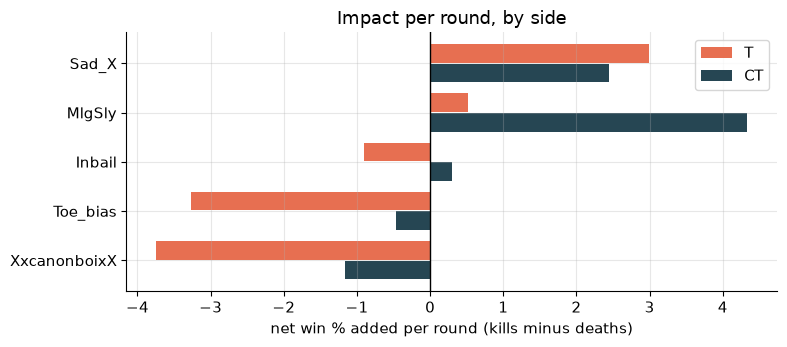

In [5]:
t = per100.sort_values("overall")
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(y + 0.2, t["T"], height=0.38, color=LOSS, label="T")
ax.barh(y - 0.2, t["CT"], height=0.38, color=US, label="CT")
ax.set_yticks(y, t.index)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("net win % added per round (kills minus deaths)")
ax.set_title("Impact per round, by side")
ax.legend()
save("04_wpa_by_player")

Read it as "percentage points of round win added per round". **+4 means that, on average, I push our win chance up 4 points every round I play.**

- **I'm the team's biggest impact on CT** (about +4.3 per round), but only about break-even on T (+0.5).
- **Sad_X is the best T-side player** (+3.0) and good on CT too.
- Toe_bias and XxcanonboixX are negative on T: their deaths cost more than their kills add.

> 📝 **My take:** yes. I think my strong point is my game sense/knowledge. My aim and reaction time are above average, but not as good as Sad_X and Inbail. But because of my game sense my aim is a lot better as well, because I know where to pre-aim and what to expect. At FACEIT 5 and 6 it seemed easier to open rounds by purely having aim fights, but now I feel like on T side it's hard for me to open, because not only are players better at aiming, their game sense probably matches or is close to mine.

In [6]:
# checking "opening rounds got harder as I levelled up": FACEIT's own entry stats (all 138 matches, both sides)
m = pd.read_parquet(P / "matches.parquet").query("my_level > 0")
m["level"] = m["my_level"].clip(4, 7).astype(int).map({4: "4", 5: "5", 6: "6", 7: "7–8"})
lv = m.groupby("level").agg(matches=("won", "size"), opening_duels=("entry_count", "sum"),
                            opening_wins=("entry_wins", "sum"), rounds=("rounds", "sum"))
lv["opening_duel_win_pct"] = lv["opening_wins"] / lv["opening_duels"]
lv["opening_duels_per_round"] = lv["opening_duels"] / lv["rounds"]
lv.round(3)

,matches,opening_duels,opening_wins,rounds,opening_duel_win_pct,opening_duels_per_round
level,,,,,,
4,28,137.0,77.0,634,0.562,0.216
5,29,117.0,66.0,625,0.564,0.187
6,45,217.0,119.0,1026,0.548,0.212
7–8,26,103.0,55.0,510,0.534,0.202


**It's a slow slide, not a cliff:** I win about **56%** of my opening duels at level 4–5, **55%** at 6 and **53%** at 7–8, while taking about the same number of them per round.
FACEIT doesn't split this by side, so I can't confirm it's T specifically, and the steps are small (about 100–200 duels per level).
It does fit the story: I'm still winning more than half, just by less as the aim *and* the game sense around me get better.

## 3. What kind of kills do I get?

In [7]:
def kill_type(r):
    if r["is_opening"]:
        return "1 opening kill"
    if r["planted"]:
        return "5 after the plant"
    if r["us_before"] <= 2:
        return "4 we're down to 1–2"
    if r["is_trade_kill"]:
        return "2 trade kill"
    return "3 other mid-round"

ok = k[k["attacker_is_my_team"] & ~k["victim_is_my_team"] & k["attacker_name"].isin(REGS)].copy()
ok["type"] = ok.apply(kill_type, axis=1)
rounds_played = mine.groupby("name").size()

value = ok.groupby("type")["wpa"].mean().rename("avg value of one kill")
per_player = ok.groupby(["type", "attacker_name"])["wpa"].sum().unstack().div(rounds_played) * 100
display(value.round(3).to_frame())
per_player.round(1)

,avg value of one kill
type,
1 opening kill,0.233
2 trade kill,0.187
3 other mid-round,0.154
4 we're down to 1–2,0.192
5 after the plant,0.167


attacker_name,Inbail,MlgSly,Sad_X,Toe_bias,XxcanonboixX
type,,,,,
1 opening kill,3.2,2.7,2.4,2.2,1.5
2 trade kill,1.6,1.5,2.1,1.2,1.2
3 other mid-round,5.2,6.5,5.3,3.4,5.1
4 we're down to 1–2,1.8,2.4,3.2,2.2,2.2
5 after the plant,1.7,2.0,2.4,2.0,1.4


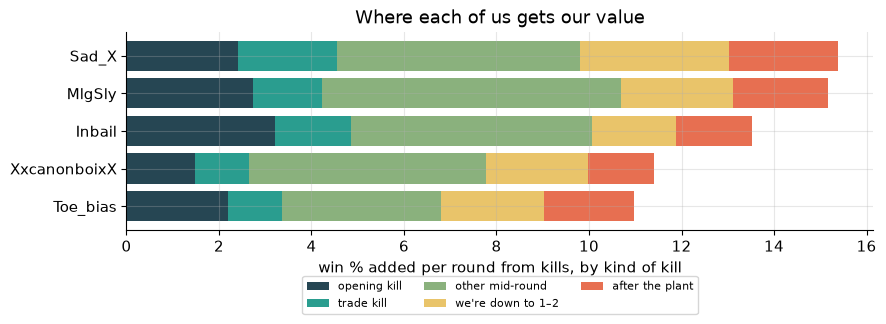

In [8]:
types = per_player.index.tolist()
cols = ["#264653", "#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51"]
order = per_player.sum().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(order))
for typ, col in zip(types, cols):
    vals = per_player.loc[typ, order].values
    ax.barh(order, vals, left=left, color=col, label=typ[2:])
    left += vals
ax.set_xlabel("win % added per round from kills, by kind of kill")
ax.set_title("Where each of us gets our value")
ax.legend(fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.45))
save("04_kill_types")

- **Opening kills are worth the most each** (~+0.23), and trade kills and late-round kills are next.
- **My value mostly comes from mid-round kills**, the fights after the opening duel when it's still 4v4 or 3v4. I have the most of those on the team.
- **Inbail** gets the most from opening kills, which fits him taking first fights on CT (notebook 02).
- **Sad_X** gets the most from **late-round and post-plant kills**: he's our closer.

## 4. Passive or aggressive? Where I stand at 0:15

In [9]:
p = pos[pos["is_my_team"]].merge(rf.loc[~rf["is_pistol"], KEY + ["map", "my_team_won"]], on=KEY)
spawn = p[p["time_s"] < 1].groupby(["map", "side"])[["X", "Y"]].median()
at15 = p[(p["time_s"] >= 14.9) & (p["time_s"] < 15.4)].join(spawn.add_suffix("_spawn"), on=["map", "side"])
at15["from_spawn"] = np.hypot(at15["X"] - at15["X_spawn"], at15["Y"] - at15["Y_spawn"])
g15 = at15.groupby(KEY)["from_spawn"]
at15["rank"] = g15.rank(ascending=False, method="first")
at15 = at15[g15.transform("size") == 5]   # all 5 alive at 0:15
at15["position"] = np.select([at15["rank"] == 1, at15["rank"] == 5], ["furthest forward", "furthest back"], "in between")
at15 = at15.merge(mine[KEY + ["name", "net_wpa"]], on=KEY + ["name"])

display(pd.crosstab([at15["name"], at15["side"]], at15["position"], normalize="index").round(2))
me = at15[at15["name"] == "MlgSly"]
me.groupby(["side", "position"]).agg(rounds=("round", "size"), net_wpa_per_round=("net_wpa", "mean"),
                                     round_win=("my_team_won", "mean")).round(3)

position           furthest back  furthest forward  in between
name         side                                             
Inbail       CT             0.17              0.10        0.73
             T              0.15              0.21        0.64
MlgSly       CT             0.29              0.12        0.58
             T              0.21              0.15        0.64
Sad_X        CT             0.18              0.25        0.58
             T              0.19              0.19        0.62
Toe_bias     CT             0.15              0.14        0.71
             T              0.34              0.08        0.58
XxcanonboixX CT             0.11              0.55        0.33
             T              0.05              0.51        0.44

rounds  net_wpa_per_round  round_win
side position                                              
CT   furthest back        130              0.061      0.615
     furthest forward      54             -0.011      0.519
     in between           258              0.046      0.655
T    furthest back         93              0.036      0.538
     furthest forward      65              0.048      0.585
     in between           275              0.009      0.545

"Forward" here means the furthest from our own spawn at 0:15 (straight-line distance, so it's rough). It's a proxy for who's playing aggressive.
XxcanonboixX shows up as "forward" a lot just because lurking takes him far from spawn.

**For me:** on **CT** I'm worth the most when I'm the one **furthest back** (+6.1 per round), and I'm actually *negative* when I'm the furthest forward (−1.1, only 54 rounds).
On **T** it's the other way round: I'm worth the most when I'm **furthest forward** (+4.8 vs +0.9 in between).
Small samples, but it hints that I should be the **anchor/rotator on CT** and **one of the first in on T**.

> 📝 **My take:** I tend to entry on T because my teammates are mostly taking too long, or not taking enough space.

## 5. Mirage: where am I worth the most?

In [10]:
km = k[k["map"] == "de_mirage"]
got = km[km["attacker_is_me"] & ~km["victim_is_my_team"]].rename(columns={"attacker_last_place_name": "place"})
lost = km[km["victim_is_me"]].rename(columns={"victim_last_place_name": "place"})
spot = (got.groupby(["my_side", "place"])["wpa"].agg(kills="size", kill_wpa="sum")
        .join(lost.groupby(["my_side", "place"])["wpa"].agg(deaths="size", death_wpa="sum"), how="outer").fillna(0))
spot["net"] = spot["kill_wpa"] + spot["death_wpa"]
spot = spot[(spot["kills"] + spot["deaths"]) >= 10].sort_values("net")
spot.round(2)

kills  kill_wpa  deaths  death_wpa   net
my_side place                                                   
CT      Jungle           12.0      1.83    14.0      -2.91 -1.08
T       Apartments       12.0      1.59    16.0      -2.56 -0.97
CT      Middle           21.0      3.64    22.0      -4.38 -0.74
T       Jungle            6.0      0.80     7.0      -1.30 -0.51
        Connector         7.0      0.98     7.0      -1.23 -0.25
CT      SnipersNest      20.0      3.32    17.0      -3.49 -0.16
T       TopofMid         31.0      6.14    32.0      -6.17 -0.03
CT      Shop              8.0      1.57    10.0      -1.59 -0.01
T       Stairs            9.0      1.57     6.0      -1.57  0.00
        CTSpawn          10.0      1.46     7.0      -1.34  0.13
        Underpass         7.0      1.36     8.0      -1.03  0.33
        Catwalk          16.0      2.79    13.0      -2.39  0.39
        BombsiteB        26.0      4.15    19.0      -3.46  0.69
        SideAlley         8.0      1.22     4.0      -0.48  0.74
        TRamp            11.0      2.24    10.0      -1.45  0.79
        BombsiteA        59.0      9.88    53.0      -8.87  1.02
CT      Underpass        22.0      4.35    14.0      -3.32  1.04
        PalaceInterior    9.0      1.69     3.0      -0.56  1.13
        Connector        19.0      3.82    14.0      -2.56  1.26
        BombsiteB        20.0      4.08    16.0      -2.69  1.39
T       PalaceInterior   25.0      4.63    21.0      -3.23  1.40
        Middle           43.0      7.40    27.0      -5.45  1.96
CT      Stairs           18.0      4.79    12.0      -2.41  2.38
        CTSpawn          40.0      6.77    27.0      -3.99  2.78
        BombsiteA        58.0     11.18    40.0      -7.71  3.48
        Catwalk          55.0      9.67    24.0      -4.08  5.59

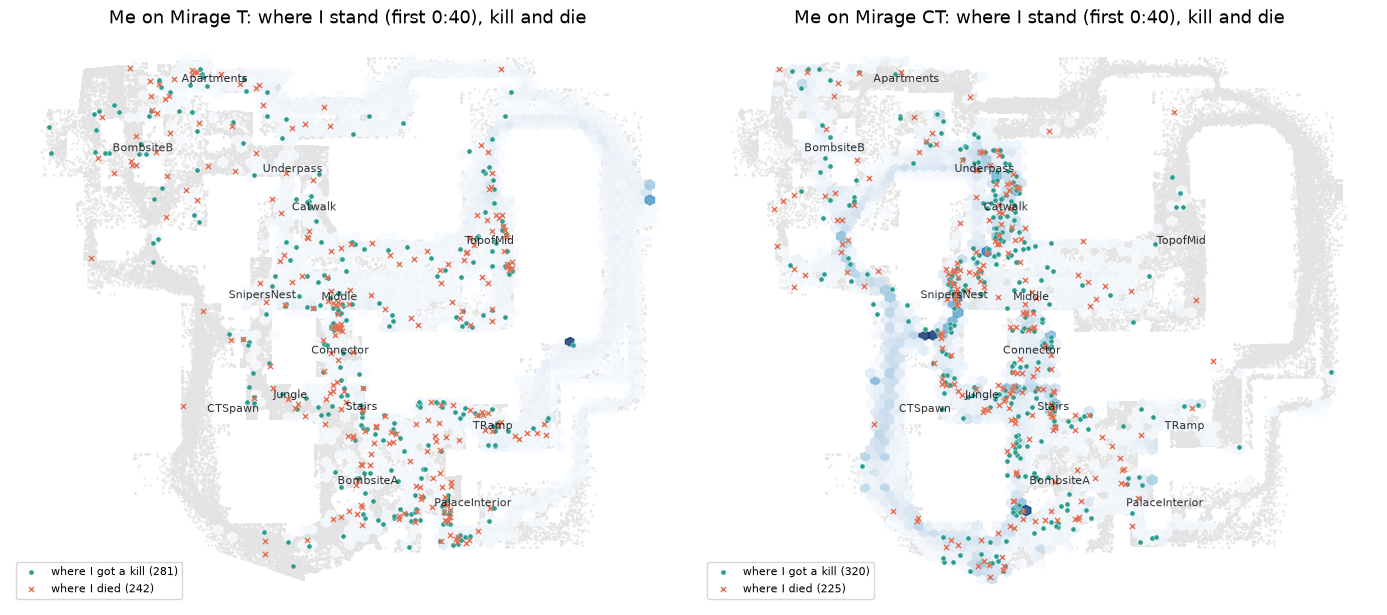

In [11]:
mir_ids = rf.loc[rf["map"] == "de_mirage", "match_id"].unique()
bg = pos[pos["match_id"].isin(mir_ids)].sample(120_000, random_state=1)
mpos = pos[pos["match_id"].isin(mir_ids) & pos["is_me"]]
labels_xy = bg[bg["place"] != ""].groupby("place")[["X", "Y"]].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, side in zip(axes, ["T", "CT"]):
    ax.scatter(bg["X"], bg["Y"], s=0.3, color="#e3e3e3", rasterized=True)
    m = mpos[(mpos["side"] == side) & (mpos["time_s"] <= 40)]
    ax.hexbin(m["X"], m["Y"], gridsize=60, cmap="Blues", mincnt=3, alpha=0.8)
    kk = got[got["my_side"] == side]
    dd = lost[lost["my_side"] == side]
    ax.scatter(kk["attacker_X"], kk["attacker_Y"], s=14, color=WIN, edgecolor="white", lw=0.3, label=f"where I got a kill ({len(kk)})")
    ax.scatter(dd["victim_X"], dd["victim_Y"], s=14, color=LOSS, marker="x", lw=1, label=f"where I died ({len(dd)})")
    for place in ["TopofMid", "Middle", "SnipersNest", "PalaceInterior", "TRamp", "Apartments", "BombsiteA",
                  "BombsiteB", "Catwalk", "Connector", "Jungle", "Underpass", "CTSpawn", "Stairs"]:
        if place in labels_xy.index:
            ax.text(*labels_xy.loc[place], place, fontsize=8, ha="center", alpha=0.8)
    ax.set_title(f"Me on Mirage {side}: where I stand (first 0:40), kill and die")
    ax.set_aspect("equal"); ax.axis("off")
    ax.legend(loc="lower left", fontsize=8)
save("04_mirage_me")

Blue = where I spend the first 40 seconds. Green dots = where I got kills, red crosses = where I died.

- **Best spot by far: CT Short/Catwalk** (+5.6 win % in total, 55 kills vs 24 deaths). CT A site and CT spawn (rotating into A) are next.
- **Worst CT spots: Jungle and Middle.** I trade about one for one there, and the deaths cost more than the kills add.
- **On T, Top of Mid is a pure coin flip** (31 kills, 32 deaths, net 0). That's the spot from notebook 02 where we die first to the Window AWP. Middle and Palace are positive for me.

> 📝 **My take:** on Mirage CT I tend to prefer playing where the most action is, so I can gain info (e.g. Short/Connector). I never play B or A anchor. Mid is always smoked off, so I don't play Window either. I'm guessing I go Jungle to rotate.

In [12]:
# checking "I go Jungle to rotate": when do my CT fights in each spot happen?
ct = km[km["my_side"] == "CT"]
rows = []
for place in ["Catwalk", "Middle", "Connector", "Jungle", "BombsiteA"]:
    d = ct[ct["victim_is_me"] & (ct["victim_last_place_name"] == place)]
    kk = ct[ct["attacker_is_me"] & (ct["attacker_last_place_name"] == place)]
    rows.append(dict(spot=place, my_kills=len(kk), my_deaths=len(d), median_death_time_s=d["time_s"].median(),
                     deaths_that_were_the_opening=d["is_opening"].mean(), deaths_after_plant=d["planted"].mean()))
pd.DataFrame(rows).set_index("spot").round(2)

,my_kills,my_deaths,median_death_time_s,deaths_that_were_the_opening,deaths_after_plant
spot,,,,,
Catwalk,55,24,23.86,0.21,0.12
Middle,21,22,20.32,0.27,0.00
Connector,19,14,36.58,0.07,0.14
Jungle,12,14,38.96,0.00,0.21
BombsiteA,58,40,37.22,0.15,0.25


**Yes, Jungle is a rotation spot for me.** My Jungle deaths happen late (median ~0:39), **none** of them is the opening death, and about a fifth come after the plant.
Compare Middle: deaths there come early (~0:20) and a quarter are the opening duel. Those are the forward mid fights that cost me.
So the pattern is: **Short = my info spot and where I'm best; Middle = early fights I lose too often; Jungle = mid-rotation fights.**

## Summary: answer to question 3

1. **I'm the team's biggest impact on CT** (+4.3 win % per round) and about **break-even on T** (+0.5). Sad_X is our best T player (+3.0).
2. **My value comes from mid-round kills**, not opening duels. Inbail is our opener, Sad_X is our closer.
3. **On CT I'm worth the most playing back** (anchor/rotator) and the least when I'm the most forward. On T it flips: I'm worth more going in first.
4. **Mirage:** CT Short is my best spot. CT Jungle/Middle and T Top of Mid are where I trade one for one.

**For the experiment:** on CT, stop taking the forward mid fights and play Short/rotate; on T, be one of the first in, but not through Top of Mid without a plan.

> 📝 **My take, in my own words:** (3–5 bullets)